# Instance segmentation: counting and separating trees in forests

In aerial forests the crowns of neighbouring trees overlap, so a semantic
"tree" mask cannot tell how many trees there are. This notebook trains a small
**multi-head anchor model** on synthetic forest tiles: objectness and box heads
(as in the detector of notebook `08_train_object_detection`) plus an
**extra mask head per anchor** that predicts a small instance mask, upscaled to
the predicted box. It **counts trees** and **separates partially overlapping
canopies**.

Training uses random **flips** (images, targets and masks together) and keeps
the best checkpoint. The model runs on Apple **MPS** (or CUDA / XPU / CPU) in
about a minute.


## Learning objectives

By the end of this notebook you will be able to:

- recall how an object becomes an **anchor-based target** (cell, anchor, box offsets);
- extend a detector with a **mask head per anchor** and a **box-relative mask target**;
- train it with a loss that combines **objectness, box, mask BCE and soft Dice** terms;
- evaluate instance masks with **instance IoU**, **detection rate** and **count MAE**,
  and compare them with a mean-count baseline;
- read the errors by canopy density (sparse, medium, dense).

### Exercises

1. Why does the mask loss add a Dice term to the pixel-wise BCE?
2. Lower `score_threshold` in `decode_anchor`: what happens to the count and to
   the instance IoU?
3. Raise `MASK_SIZE`: does the IoU improve, and at what training cost?

**What to expect.** (1) BCE scores every mask pixel separately, so a mask that
covers few pixels is dominated by the easy background; Dice measures the overlap
of the whole mask, which balances the two. (2) A lower `score_threshold`
reports more objects (higher count) with more false positives, so recall rises
while precision and instance IoU fall. (3) A larger `MASK_SIZE` sharpens mask
boundaries and usually gives a small IoU gain, at a memory/time cost in the mask
head (its `1x1` convolution has `A * MASK_SIZE^2` output channels).


### Key terms

- **anchor** — a prototypical box shape; each `(cell, anchor)` is one prediction
  slot.
- **objectness** — the score that a slot contains an object (here a tree).
- **NMS** — non-maximum suppression; removes duplicate boxes: boxes are visited
  by decreasing score and a box is dropped when its IoU with an already kept box
  exceeds a threshold $\tau$.
- **box-relative (instance) mask** — a mask predicted inside an object's own box,
  cropped and resized to `MASK_SIZE`.
- **instance IoU / detection rate** — overlap of a true tree with its best
  predicted mask, and the fraction of trees recovered with IoU >= 0.5.
- **count MAE / MAPE** — mean absolute / relative error of the predicted tree
  count.


In [1]:
# Google Colab does not preinstall torchinfo (a quiet no-op when it is already present).
%pip install -q torchinfo

Note: you may need to restart the kernel to use updated packages.


In [2]:
# On Google Colab, install mplsyn from GitHub (locally, the editable install is kept).
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install -q git+https://github.com/ogrisel/mplsyn.git")

In [3]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)


def pick_device():
    """Best available device: CUDA, then Apple MPS, then Intel XPU, else CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return "mps"
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return "xpu"
    return "cpu"


DEVICE = pick_device()
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("No GPU backend available: training will run on CPU (slower).")

torch 2.15.0 | device mps


## Task: a mask per anchor on the detector

**Use case.** In aerial forests the crowns of neighbouring trees overlap, so a
single "tree" class cannot tell how many trees there are. We extend the anchor
detector of notebook 08 into a **multi-head** model that predicts an **instance mask per
anchor**:

- **objectness head** and **box head** — as in notebook 08;
- **mask head per anchor** — for every `(cell, anchor)`, a small
  `MASK_SIZE x MASK_SIZE` mask, upscaled to the predicted box at inference.

**Training target:** the GT instance mask **cropped to its box** and resized to
`MASK_SIZE` (a Mask R-CNN-style, box-relative mask). The forests are generated
with exact instance masks, from sparse stands (a handful of trees) to dense
canopy (dozens of overlapping crowns), plus an **urban avenue** layout (regular
rows of street trees lining a road) and scattered **boulders** under the canopy
that the model must not count as trees.


In [4]:
from mplsyn.datasets import load_forest_data

FOREST_SIZE = 64
FOREST_GRID = 16

forest_images, forest_instances = load_forest_data(400, size=FOREST_SIZE)
print("forest data", forest_images.shape)

forest data (400, 64, 64, 3)


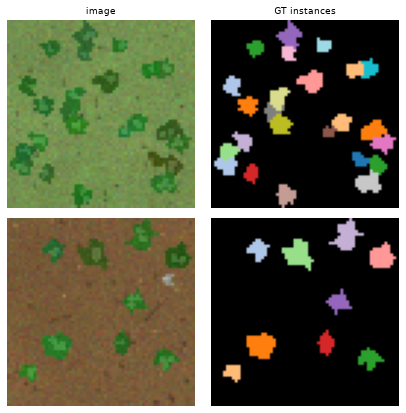

In [5]:
def colorize_instances(instance_map):
    """Map integer instance ids to a repeating qualitative colormap."""
    color_map = plt.get_cmap("tab20")
    rgb = np.zeros((*instance_map.shape, 3))
    for instance_id in range(1, int(instance_map.max()) + 1):
        rgb[instance_map == instance_id] = color_map(instance_id % 20)[:3]
    return rgb


fig, axes = plt.subplots(2, 2, figsize=(6, 6), dpi=70)
for sample_idx in range(2):
    axes[sample_idx, 0].imshow(forest_images[sample_idx])
    axes[sample_idx, 1].imshow(colorize_instances(forest_instances[sample_idx]))
for ax, title in zip(axes[0], ["image", "GT instances"]):
    ax.set_title(title, fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**Figure read-out.** Two forest tiles with their ground-truth instance maps; distinct colours are distinct trees, so overlapping crowns can still be told apart. These maps are the labels the mask head is trained on.

## Anchor targets: recap from notebook 08

The detection notebook derived the anchor-based target encoding; here is what we
reuse, with the notation of this notebook. $S=16$ is the grid size (cells per
side, stride 4 px on a 64 px tile), $A=3$ the number of anchors per cell, $B$ the
batch size, $P$ the number of positive slots (ground-truth trees) in a batch and
$N=B\,S^2A$ the number of slots (a *slot* is one `(cell, anchor)` pair). There is
a single class, so there is no class term.

Boxes are normalised, $(x_0,y_0,x_1,y_1)\in[0,1]^4$, with the $y$ axis pointing
**up** while grid rows are counted from the **top**, hence the $1-c_y$ below. A
tree box has centre $(c_x,c_y)=\big(\tfrac{x_0+x_1}{2},\tfrac{y_0+y_1}{2}\big)$ and
size $(w,h)=(x_1-x_0,\;y_1-y_0)$. It is assigned to the anchor $(a_w,a_h)$ with
the best **shape IoU**, the IoU of the two boxes once they share the same centre,

$$\mathrm{IoU}_{\text{shape}}=\frac{\min(w,a_w)\,\min(h,a_h)}{w\,h+a_w a_h-\min(w,a_w)\,\min(h,a_h)},$$

and to the cell that contains its centre, $\text{col}=\lfloor c_x S\rfloor$,
$\text{row}=\lfloor (1-c_y)S\rfloor$. That slot becomes a positive
(objectness $o_s=1$) and stores the box targets

$$t_x = c_x S - \text{col},\quad t_y = (1-c_y)S - \text{row},\quad
t_w = \log\frac{w}{a_w},\quad t_h = \log\frac{h}{a_h}.$$

The network regresses these four numbers **directly** (raw outputs
$\hat t_x,\hat t_y,\hat t_w,\hat t_h$, Smooth-L1 loss, no squashing function). At
inference the encoding is inverted,

$$b_x = \frac{\text{col}+\hat t_x}{S},\quad
b_y = 1-\frac{\text{row}+\hat t_y}{S},\quad
b_w = a_w e^{\hat t_w},\quad b_h = a_h e^{\hat t_h}.$$

The anchors come from k-means on the box shapes of the training forests. Tree
sizes span a narrow range, so, unlike in the urban detector, the raw
$(w,h)$ are clustered (`log_space=False`) instead of $(\log w,\log h)$.


In [6]:
from mplsyn.datasets import forest_targets, kmeans_anchors, tree_box

N_FOREST_ANCHORS = 3

forest_boxes = []
for instance_map in forest_instances:
    for instance_id in range(1, int(instance_map.max()) + 1):
        x0, y0, x1, y1 = tree_box(instance_map, instance_id)
        forest_boxes.append((x1 - x0, y1 - y0))
FOREST_ANCHORS = kmeans_anchors(forest_boxes, N_FOREST_ANCHORS, log_space=False)
print("tree anchors (width, height):", np.round(FOREST_ANCHORS, 3).tolist())

forest_objectness, forest_box_target, forest_ids = [], [], []
for instance_map in forest_instances:
    obj, box, ids = forest_targets(instance_map, FOREST_ANCHORS, FOREST_GRID)
    forest_objectness.append(obj)
    forest_box_target.append(box)
    forest_ids.append(ids)
forest_objectness = torch.from_numpy(np.stack(forest_objectness))
forest_box_target = torch.from_numpy(np.stack(forest_box_target))
forest_ids = torch.from_numpy(np.stack(forest_ids))


def forest_instance_scores(ground_truth, predicted):
    """Best IoU of each GT instance with any predicted instance."""
    n_gt, n_pred = int(ground_truth.max()), int(predicted.max())
    if n_gt == 0:
        return [], 0
    joint = (predicted.astype(np.int64) * (n_gt + 1) + ground_truth).ravel()
    intersection = np.bincount(joint, minlength=(n_pred + 1) * (n_gt + 1)).reshape(
        n_pred + 1, n_gt + 1
    )
    area_pred = np.bincount(predicted.ravel(), minlength=n_pred + 1)
    area_gt = np.bincount(ground_truth.ravel(), minlength=n_gt + 1)
    intersections, matched = [], 0
    for gt_id in range(1, n_gt + 1):
        best = 0.0
        for pred_id in range(1, n_pred + 1):
            union = area_pred[pred_id] + area_gt[gt_id] - intersection[pred_id, gt_id]
            if union:
                best = max(best, intersection[pred_id, gt_id] / union)
        intersections.append(best)
        matched += best >= 0.5
    return intersections, matched

tree anchors (width, height): [[0.091, 0.092], [0.121, 0.12], [0.153, 0.153]]


## Loss and metrics

**Loss.** Let $\sigma(z)=1/(1+e^{-z})$, $z^{o}_s$ the objectness logit of slot $s$,
$\mathcal P=\{s: o_s=1\}$ the $P$ positive slots, $t_s,\hat t_s\in\mathbb R^4$ the
target and predicted box parameters, $m_s\in[0,1]^{M\times M}$ the box-relative
target mask of slot $s$, $z^{m}_{sj}$ the mask logits and
$\hat m_{sj}=\sigma(z^{m}_{sj})$ the predicted mask ($M=$ `MASK_SIZE`, $j$ indexing
the $M^2$ mask pixels). The total loss is

$$\mathcal{L}=\mathcal{L}_{\text{obj}}+2\,\mathcal{L}_{\text{box}}+4\,\big(\mathcal{L}_{\text{mask-BCE}}+\mathcal{L}_{\text{Dice}}\big),$$

with:
- objectness: BCE-with-logits over **all** $N$ slots with a positive weight $w_{+}=10$
  to counter the huge number of negatives (trees are sparse),
  $$\mathcal{L}_{\text{obj}}=-\frac{1}{N}\sum_{s=1}^{N}\Big[w_{+}\,o_s\log\sigma(z^{o}_s)+(1-o_s)\log\big(1-\sigma(z^{o}_s)\big)\Big];$$
- box: Smooth-L1 on the positive slots only, averaged over their $4P$ values,
  $$\mathcal{L}_{\text{box}}=\frac{1}{4P}\sum_{s\in\mathcal P}\sum_{k\in\{x,y,w,h\}}\mathrm{smooth}_{L1}\big(\hat t_{s,k}-t_{s,k}\big),\qquad
  \mathrm{smooth}_{L1}(d)=\begin{cases}\tfrac12 d^2 & |d|<1\\ |d|-\tfrac12 & \text{otherwise;}\end{cases}$$
- mask BCE: the pixel-wise BCE with positive weight 3, averaged over the $P\,M^2$ mask
  pixels of the positive slots;
- soft Dice, the differentiable version of $1-\mathrm{Dice}$ (the $+1$ keeps it defined for empty masks),
  $$\mathcal{L}_{\text{Dice}}=\frac{1}{P}\sum_{s\in\mathcal P}\left(1-\frac{2\sum_j \hat m_{sj}\,m_{sj}+1}{\sum_j \hat m_{sj}+\sum_j m_{sj}+1}\right).$$

BCE penalises every pixel separately while Dice measures the overlap of the whole
mask, which helps when the mask covers few pixels.

**Metrics.** For each ground-truth tree $g$ with mask $G_g$,
$\mathrm{IoU}_g=\max_{p}\frac{|M_p\cap G_g|}{|M_p\cup G_g|}$ over the predicted
instance masks $M_p$ (the predictions are painted into one label map, so where two
predicted masks overlap the later one wins; there is no one-to-one matching, two
ground-truth trees may share their best prediction). The **instance IoU** is the
mean of $\mathrm{IoU}_g$ over the trees of the split and the **detection rate** is
the fraction of trees with $\mathrm{IoU}_g\ge 0.5$. For the tree count, with
$\hat n_j$ and $n_j$ the predicted and true counts of image $j$ among $J$ images,

$$\mathrm{MAE}=\frac{1}{J}\sum_{j=1}^{J}|\hat n_j-n_j|,\qquad \mathrm{MAPE}=\frac{1}{J}\sum_{j=1}^{J}\frac{|\hat n_j-n_j|}{\max(n_j,1)}.$$

The notebook also plots the **training and validation loss curves** (plus count
error and IoU vs epoch) and a **mean-count baseline** that always predicts the
average training count $\hat n_j=\bar n_{\text{train}}$ without looking at the image.


In [7]:
def box_iou(box_a, box_b):
    """IoU of two (x0, y0, x1, y1) boxes (bottom-left origin)."""
    left = max(box_a[0], box_b[0])
    bottom = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2])
    top = min(box_a[3], box_b[3])
    intersection = max(0.0, right - left) * max(0.0, top - bottom)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


MASK_SIZE = 24  # per-anchor mask resolution (finer = less fragmented masks)


class AnchorMaskDetector(nn.Module):
    """Multi-head anchor detector whose mask head predicts one mask per anchor."""

    def __init__(self, n_anchors, mask_size=MASK_SIZE, base=32):
        super().__init__()
        self.n_anchors = n_anchors
        self.mask_size = mask_size

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.backbone = nn.Sequential(block(3, base, 2), block(base, base * 2, 2))
        self.objectness_head = nn.Conv2d(base * 2, n_anchors, 1)
        self.box_head = nn.Conv2d(base * 2, n_anchors * 4, 1)
        # One small mask per (cell, anchor): A * mask_size * mask_size channels.
        self.mask_conv = nn.Conv2d(base * 2, base * 2, 3, 1, 1)
        self.mask_head = nn.Conv2d(base * 2, n_anchors * mask_size * mask_size, 1)

    def forward(self, image_batch):
        features = self.backbone(image_batch)
        n = len(image_batch)
        objectness = self.objectness_head(features).permute(0, 2, 3, 1)
        box = (
            self.box_head(features)
            .view(n, self.n_anchors, 4, FOREST_GRID, FOREST_GRID)
            .permute(0, 3, 4, 1, 2)
        )
        mask = self.mask_head(F.relu(self.mask_conv(features))).view(
            n, self.n_anchors, self.mask_size, self.mask_size, FOREST_GRID, FOREST_GRID
        )
        return objectness, box, mask


def forest_nms(candidates, iou_threshold=0.5):
    """Greedy NMS over (score, box, payload) detections."""
    candidates = sorted(candidates, key=lambda candidate: -candidate[0])
    kept = []
    for candidate in candidates:
        if all(box_iou(candidate[1], other[1]) <= iou_threshold for other in kept):
            kept.append(candidate)
    return kept


def decode_anchor(
    objectness, box_pred, mask, anchors, score_threshold=0.5, iou_threshold=0.4, top_k=45
):
    """Decode per-anchor-mask outputs into (score, box, mask_block) detections."""
    objectness = torch.sigmoid(objectness)
    # Offsets in the cell are regressed raw onto t_x, t_y (see the loss): no sigmoid.
    center_x = box_pred[..., 0]
    center_y = box_pred[..., 1]
    width = box_pred[..., 2]
    height = box_pred[..., 3]
    results = []
    for image_idx in range(len(objectness)):
        candidates = []
        for anchor_idx, (anchor_w, anchor_h) in enumerate(anchors):
            for row in range(FOREST_GRID):
                for col in range(FOREST_GRID):
                    score = float(objectness[image_idx, row, col, anchor_idx])
                    if score < score_threshold:
                        continue
                    cx = (col + float(center_x[image_idx, row, col, anchor_idx])) / FOREST_GRID
                    cy = 1 - (row + float(center_y[image_idx, row, col, anchor_idx])) / FOREST_GRID
                    w = anchor_w * float(torch.exp(width[image_idx, row, col, anchor_idx]))
                    h = anchor_h * float(torch.exp(height[image_idx, row, col, anchor_idx]))
                    box = (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)
                    mask_block = mask[image_idx, anchor_idx, :, :, row, col].cpu()
                    candidates.append((score, box, mask_block))
        results.append(forest_nms(candidates, iou_threshold)[:top_k])
    return results


def crop_resize(mask_array, out_size):
    """Crop a binary mask to its bbox and resize to out_size x out_size."""
    rows, cols = np.nonzero(mask_array)
    crop = mask_array[rows.min() : rows.max() + 1, cols.min() : cols.max() + 1].astype(np.float32)
    tensor = torch.from_numpy(crop)[None, None]
    return F.interpolate(tensor, size=(out_size, out_size), mode="bilinear", align_corners=False)[
        0, 0
    ].numpy()


def per_anchor_map(detections):
    """Resize each detection's mask block to its box and paint instances."""
    labels = np.zeros((FOREST_SIZE, FOREST_SIZE), np.int32)
    grid_y, grid_x = np.mgrid[0:FOREST_SIZE, 0:FOREST_SIZE]
    for instance_id, (score, box, mask_block) in enumerate(detections, start=1):
        x0, y0, x1, y1 = box
        px0 = max(int(round(x0 * FOREST_SIZE)), 0)
        px1 = min(int(round(x1 * FOREST_SIZE)), FOREST_SIZE)
        py0 = max(int(round((1 - y1) * FOREST_SIZE)), 0)
        py1 = min(int(round((1 - y0) * FOREST_SIZE)), FOREST_SIZE)
        if px1 <= px0 or py1 <= py0:
            continue
        upsampled = torch.sigmoid(
            F.interpolate(
                mask_block[None, None],
                size=(py1 - py0, px1 - px0),
                mode="bilinear",
                align_corners=False,
            )
        )[0, 0].numpy()
        full = np.zeros((FOREST_SIZE, FOREST_SIZE), np.float32)
        full[py0:py1, px0:px1] = upsampled
        in_box = (
            (grid_x >= x0 * FOREST_SIZE)
            & (grid_x <= x1 * FOREST_SIZE)
            & (grid_y >= (1 - y1) * FOREST_SIZE)
            & (grid_y <= (1 - y0) * FOREST_SIZE)
        )
        labels[(full > 0.5) & in_box & (labels == 0)] = instance_id
    return labels


forest_model = AnchorMaskDetector(N_FOREST_ANCHORS).to(DEVICE)
n_parameters = sum(p.numel() for p in forest_model.parameters())
print(f"{n_parameters / 1e3:.1f} k parameters")

216.0 k parameters


In [8]:
from torchinfo import summary

# One image through the network (batch size 1): shapes and counts are per sample.
print(
    summary(
        forest_model,
        input_size=(1, 3, FOREST_SIZE, FOREST_SIZE),
        depth=2,
        mode="eval",
        device=DEVICE,
        verbose=0,
        col_names=("input_size", "output_size", "num_params", "mult_adds"),
    )
)

# torchinfo only reports the first of the three outputs on the root row: print them all.
was_training = forest_model.training
forest_model.eval()
with torch.no_grad():
    dummy = torch.zeros(1, 3, FOREST_SIZE, FOREST_SIZE, device=DEVICE)
    output_shapes = [tuple(output.shape) for output in forest_model(dummy)]
forest_model.train(was_training)
print("outputs (objectness, box, mask):", output_shapes)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
AnchorMaskDetector                       [1, 3, 64, 64]            [1, 16, 16, 3]            --                        --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 64, 16, 16]           --                        --
│    └─Sequential: 2-1                   [1, 3, 64, 64]            [1, 32, 32, 32]           10,208                    10,322,048
│    └─Sequential: 2-2                   [1, 32, 32, 32]           [1, 64, 16, 16]           55,552                    14,156,032
├─Conv2d: 1-2                            [1, 64, 16, 16]           [1, 3, 16, 16]            195                       49,920
├─Conv2d: 1-3                            [1, 64, 16, 16]           [1, 12, 16, 16]           780                       199,680
├─Conv2d: 1-4                            [1, 64, 16, 16]           [1, 64, 16, 16]           36,928               

### What `torchinfo` tells us about `AnchorMaskDetector`

Numbers below are per `64 x 64` RGB image (batch size 1). The root row of the table only lists the first of the three outputs, so the shapes of all of them come from the extra print below it.

- **Output shapes.** The backbone has the same design as `AnchorDetector` of notebook 08: `[1, 3, 64, 64] -> [1, 64, 16, 16]`. Three heads then read that map: objectness `[1, 16, 16, 3]` (one logit per cell and anchor), box `[1, 16, 16, 3, 4]` and mask `[1, 3, 24, 24, 16, 16]` (a `24x24` mask for every anchor of every cell, obtained from a `1x1` convolution with 3 x 24 x 24 = 1,728 channels).
- **The mask head dominates the outputs.** It emits 442,368 numbers per image, against 768 for objectness and 3,072 for boxes: 99 % of all outputs. Almost all of them are useless, since only the few cells that contain a tree centre have a mask target. That is why the training loss selects the masks at the **positive cells only** (`out_mask[batch_index, anchor_index, :, :, row_index, col_index]`).
- **Parameters (215,983, about 216 k).** The mask branch (`mask_conv` 36,928 + `mask_head` 112,320) holds 149,248 of them (69 %); `mask_head` alone is 52 %. The backbone has 65,760 (30 %), the same weights as the backbone of the detector of notebook 08, and the objectness and box heads together just 975 (0.5 %). Giving each anchor a mask roughly triples the size of the model compared with the 70 k detector of notebook 08.
- **Compute (about 63 M multiply-adds).** The mask branch costs 38 M (61 %); the two heads that only localise cost 0.25 M.


### What the mask head actually learns (visual)

The mask target is **box-relative** (Mask R-CNN style): the GT instance mask is
**cropped to its bounding box and resized** to `MASK_SIZE x MASK_SIZE`. The head
therefore never sees absolute position — only the shape of the object inside
its own box. The figure shows one forest tree: the image, the instance map, the
chosen instance with its box, and the small target the head is trained on.

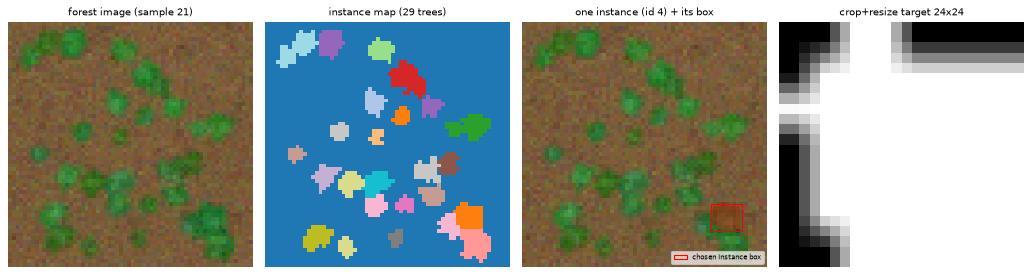

In [9]:
import matplotlib.patches as mpatches

# Pick a validation forest with several trees and inspect one instance.
sample_index = int(np.argmax([int(inst.max()) for inst in forest_instances[:80]]))
image = forest_images[sample_index]
instance_map = forest_instances[sample_index]
# Use the largest fully-visible instance (not clipped at the border) so both
# the box and the cropped target are easy to read.
areas = np.bincount(instance_map.ravel())
areas[0] = 0
candidates = []
for candidate_id in np.nonzero(areas)[0]:
    candidate_rows, candidate_cols = np.nonzero(instance_map == candidate_id)
    if (
        candidate_rows.min() > 2
        and candidate_cols.min() > 2
        and candidate_rows.max() < FOREST_SIZE - 3
        and candidate_cols.max() < FOREST_SIZE - 3
    ):
        candidates.append((int(areas[candidate_id]), int(candidate_id)))
instance_id = max(candidates)[1] if candidates else int(np.argmax(areas))
instance_mask = instance_map == instance_id
rows, cols = np.nonzero(instance_mask)
bbox = (cols.min(), rows.min(), cols.max() + 1, rows.max() + 1)
mask_target = crop_resize(instance_mask, MASK_SIZE)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), dpi=80)
axes[0].imshow(image)
axes[0].set_title(f"forest image (sample {sample_index})", fontsize=9)
axes[1].imshow(instance_map, cmap="tab20")
axes[1].set_title(f"instance map ({int(instance_map.max())} trees)", fontsize=9)
axes[2].imshow(image)
axes[2].add_patch(
    mpatches.Rectangle(
        (bbox[0], bbox[1]),
        bbox[2] - bbox[0],
        bbox[3] - bbox[1],
        edgecolor="red",
        facecolor="none",
        linewidth=1.0,
    )
)
axes[2].imshow(np.where(instance_mask, 1.0, np.nan), cmap="autumn", alpha=0.4)
axes[2].set_title(f"one instance (id {instance_id}) + its box", fontsize=9)
axes[3].imshow(mask_target, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[3].set_title(f"crop+resize target {MASK_SIZE}x{MASK_SIZE}", fontsize=9)
axes[2].legend(
    handles=[mpatches.Patch(facecolor="none", edgecolor="red", label="chosen instance box")],
    loc="lower right",
    fontsize=6,
    framealpha=0.7,
)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Figure read-out.** One forest instance: image, instance map, the chosen instance (red box) and the crop+resize mask target the head learns - a box-relative mask.

### Training recipe (instance)

| item | value |
|---|---|
| model | detector + per-anchor mask head, 3 anchors on a 16x16 grid (216 k params) |
| input | 64x64 forest tiles |
| loss | objectness + 2*box + 4*(mask BCE + Dice) |
| optimiser | AdamW, lr 2e-3 |
| epochs / batch | 70 / 16 |
| augmentation | horizontal/vertical flips (images, targets and masks together) |
| data | 300 train / 56 val / 44 test |

In [10]:
forest_images_device = torch.from_numpy(
    forest_images.astype(np.float32).transpose(0, 3, 1, 2) / 255.0
)
n_forest_val, n_forest_test = 56, 44
cut = n_forest_val + n_forest_test
train_images = forest_images_device[:-cut]
train_objectness = forest_objectness[:-cut]
train_box_target = forest_box_target[:-cut]
train_instances = forest_instances[:-cut]
val_images_device = forest_images_device[-cut:-n_forest_test]
val_objectness = forest_objectness[-cut:-n_forest_test]
val_box_target = forest_box_target[-cut:-n_forest_test]
val_ids = forest_ids[-cut:-n_forest_test]
val_instances = forest_instances[-cut:-n_forest_test]
test_images_device = forest_images_device[-n_forest_test:]
test_instances = forest_instances[-n_forest_test:]


def flip_forest_batch(images, objectness, box_target, ids, instance_maps, rng):
    """Random flips; keep images, targets, instance ids and masks consistent."""
    if rng.random() < 0.5:  # horizontal
        images = torch.flip(images, [3])
        objectness = torch.flip(objectness, [2]).clone()
        box_target = torch.flip(box_target, [2]).clone()
        box_target[..., 0] = 1 - box_target[..., 0]
        ids = torch.flip(ids, [2]).clone()
        instance_maps = [np.flip(instance_map, axis=1).copy() for instance_map in instance_maps]
    if rng.random() < 0.5:  # vertical
        images = torch.flip(images, [2])
        objectness = torch.flip(objectness, [1]).clone()
        box_target = torch.flip(box_target, [1]).clone()
        box_target[..., 1] = 1 - box_target[..., 1]
        ids = torch.flip(ids, [1]).clone()
        instance_maps = [np.flip(instance_map, axis=0).copy() for instance_map in instance_maps]
    return images, objectness, box_target, ids, instance_maps


def forest_split_loss(images, objectness_target, box_target, ids, instance_maps):
    """Total instance-model loss on a split (matches the training objective)."""
    out_objectness, out_box, out_mask = forest_model(images)
    positive = objectness_target > 0.5
    objectness_loss = F.binary_cross_entropy_with_logits(
        out_objectness, objectness_target, pos_weight=torch.tensor(10.0, device=DEVICE)
    )
    box_loss = F.smooth_l1_loss(out_box[positive], box_target[positive])
    batch_index, row_index, col_index, anchor_index = positive.nonzero(as_tuple=True)
    selected_masks = out_mask[batch_index, anchor_index, :, :, row_index, col_index]
    positive_cpu = positive.cpu()
    instance_ids = ids[positive_cpu].tolist()
    image_in_batch = positive_cpu.nonzero(as_tuple=True)[0].tolist()
    mask_target = torch.from_numpy(
        np.stack(
            [
                crop_resize(instance_maps[image_in_batch[k]] == instance_ids[k], MASK_SIZE)
                for k in range(len(instance_ids))
            ]
        )
    ).to(DEVICE)
    probability = torch.sigmoid(selected_masks)
    intersection = (probability * mask_target).sum((1, 2))
    union = probability.sum((1, 2)) + mask_target.sum((1, 2))
    dice = (1 - (2 * intersection + 1) / (union + 1)).mean()
    mask_bce = F.binary_cross_entropy_with_logits(
        selected_masks, mask_target, pos_weight=torch.tensor(3.0, device=DEVICE)
    )
    return objectness_loss + 2 * box_loss + 4 * (mask_bce + dice)


optimizer = torch.optim.AdamW(forest_model.parameters(), lr=2e-3)
EPOCHS, BATCH_SIZE = 70, 16
rng = np.random.default_rng(0)
best_iou, best_state = -1.0, None
history = []
started = time.time()
for epoch in range(EPOCHS):
    forest_model.train()
    permutation = torch.randperm(len(train_images), device="cpu")
    running_loss = 0.0
    for start in range(0, len(train_images), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        batch_images, batch_objectness, batch_box, batch_ids, batch_instances = flip_forest_batch(
            train_images[batch_indices],
            train_objectness[batch_indices],
            train_box_target[batch_indices],
            forest_ids[batch_indices],
            [train_instances[index] for index in batch_indices.tolist()],
            rng,
        )
        batch_images = batch_images.to(DEVICE)
        batch_objectness = batch_objectness.to(DEVICE)
        batch_box = batch_box.to(DEVICE)
        optimizer.zero_grad()
        # Each positive predicts a small mask; the target is the GT instance mask
        # cropped to its box, so the mask lives in the box frame (Mask R-CNN style).
        objectness, box_prediction, mask = forest_model(batch_images)
        positive = batch_objectness > 0.5
        objectness_loss = F.binary_cross_entropy_with_logits(
            objectness, batch_objectness, pos_weight=torch.tensor(10.0, device=DEVICE)
        )
        box_loss = F.smooth_l1_loss(box_prediction[positive], batch_box[positive])
        # Gather the predicted mask block of every positive and its box-relative GT.
        batch_index, row_index, col_index, anchor_index = positive.nonzero(as_tuple=True)
        selected_masks = mask[batch_index, anchor_index, :, :, row_index, col_index]
        positive_cpu = positive.cpu()
        instance_ids = batch_ids[positive_cpu].tolist()
        image_in_batch = positive_cpu.nonzero(as_tuple=True)[0].tolist()
        mask_target = torch.from_numpy(
            np.stack(
                [
                    crop_resize(batch_instances[image_in_batch[k]] == instance_ids[k], MASK_SIZE)
                    for k in range(len(instance_ids))
                ]
            )
        ).to(DEVICE)
        probability = torch.sigmoid(selected_masks)
        intersection = (probability * mask_target).sum((1, 2))
        union = probability.sum((1, 2)) + mask_target.sum((1, 2))
        dice = (1 - (2 * intersection + 1) / (union + 1)).mean()
        mask_bce = F.binary_cross_entropy_with_logits(
            selected_masks, mask_target, pos_weight=torch.tensor(3.0, device=DEVICE)
        )
        loss = objectness_loss + 2 * box_loss + 4 * (mask_bce + dice)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        forest_model.eval()
        with torch.no_grad():
            validation_loss = float(
                forest_split_loss(
                    val_images_device.to(DEVICE),
                    val_objectness.to(DEVICE),
                    val_box_target.to(DEVICE),
                    val_ids,
                    val_instances,
                ).item()
            )
            objectness, box_prediction, mask = forest_model(val_images_device.to(DEVICE))
        detections = decode_anchor(
            objectness.cpu(), box_prediction.cpu(), mask.cpu(), FOREST_ANCHORS
        )
        count_errors, count_mape, intersections, matched, total = [], [], [], 0, 0
        for sample_idx in range(n_forest_val):
            labels = per_anchor_map(detections[sample_idx])
            ground_truth = val_instances[sample_idx]
            gt_count = max(int(ground_truth.max()), 1)
            predicted_count = len(detections[sample_idx])
            count_errors.append(abs(predicted_count - gt_count))
            count_mape.append(abs(predicted_count - gt_count) / gt_count)
            total += gt_count
            sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
            intersections += sample_ious
            matched += sample_matched
        mean_iou = float(np.mean(intersections))
        if mean_iou > best_iou:
            best_iou = mean_iou
            best_state = copy.deepcopy(forest_model.state_dict())
        history.append(
            (
                epoch,
                running_loss / len(train_images),
                validation_loss,
                float(np.mean(count_errors)),
                mean_iou,
                matched / total,
            )
        )
        print(
            f"epoch {epoch:3d} | loss {running_loss / len(train_images):.3f}"
            f" | val loss {validation_loss:.3f}"
            f" | count MAE {np.mean(count_errors):.2f} | MAPE {100 * np.mean(count_mape):.0f}%"
            f" | inst IoU {mean_iou:.3f}"
            f" | best {best_iou:.3f} | detect {matched}/{total} | {time.time() - started:.0f}s"
        )
forest_model.load_state_dict(best_state)
train_time = time.time() - started
print(f"best instance IoU {best_iou:.3f} | training time {train_time:.1f} s")

epoch   9 | loss 3.601 | val loss 3.626 | count MAE 0.86 | MAPE 5% | inst IoU 0.637 | best 0.637 | detect 819/915 | 8s


epoch  19 | loss 3.208 | val loss 3.295 | count MAE 0.79 | MAPE 5% | inst IoU 0.686 | best 0.686 | detect 840/915 | 14s


epoch  29 | loss 3.007 | val loss 3.151 | count MAE 0.93 | MAPE 6% | inst IoU 0.711 | best 0.711 | detect 849/915 | 21s


epoch  39 | loss 2.861 | val loss 3.111 | count MAE 0.77 | MAPE 5% | inst IoU 0.708 | best 0.711 | detect 850/915 | 28s


epoch  49 | loss 2.760 | val loss 3.120 | count MAE 1.21 | MAPE 8% | inst IoU 0.718 | best 0.718 | detect 851/915 | 34s


epoch  59 | loss 2.669 | val loss 3.053 | count MAE 0.91 | MAPE 5% | inst IoU 0.723 | best 0.723 | detect 859/915 | 41s


epoch  69 | loss 2.624 | val loss 3.058 | count MAE 1.32 | MAPE 8% | inst IoU 0.710 | best 0.723 | detect 853/915 | 47s
best instance IoU 0.723 | training time 47.3 s


validation count MAE 0.91 trees | MAPE 5% | instance IoU 0.723 | detection 859/915 = 0.94
mean-count baseline MAE 5.40 trees (model 0.91)


test       count MAE 0.80 trees | MAPE 6% | instance IoU 0.733 | detection 624/654 = 0.95


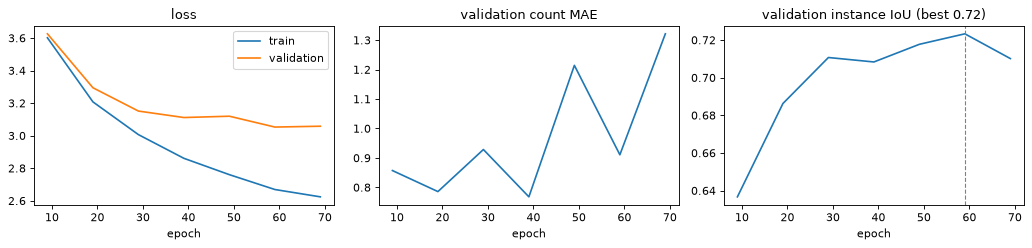

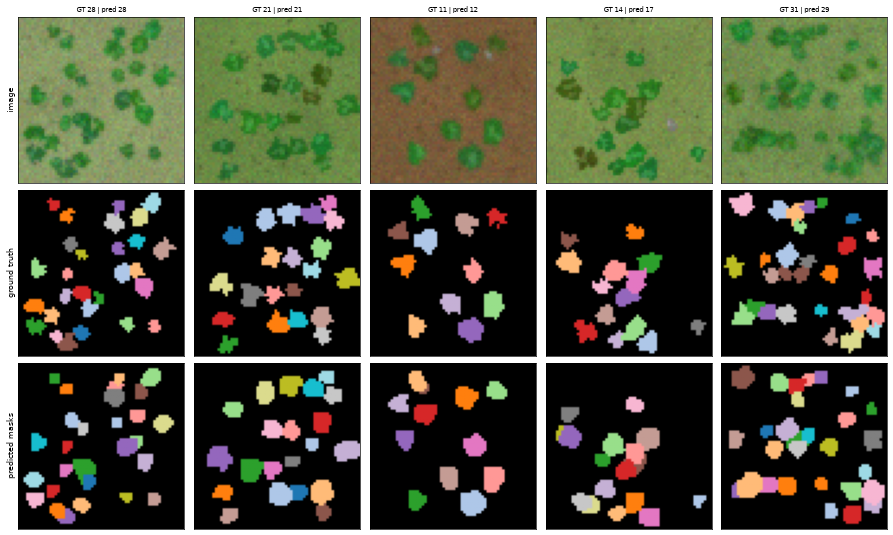

In [11]:
forest_model.eval()
with torch.no_grad():
    objectness, box_prediction, mask = forest_model(val_images_device.to(DEVICE))
detections = decode_anchor(objectness.cpu(), box_prediction.cpu(), mask.cpu(), FOREST_ANCHORS)

count_errors, count_mape, intersections, matched, total = [], [], [], 0, 0
predicted_labels = []
for sample_idx in range(n_forest_val):
    labels = per_anchor_map(detections[sample_idx])
    predicted_labels.append(labels)
    ground_truth = val_instances[sample_idx]
    gt_count = max(int(ground_truth.max()), 1)
    predicted_count = len(detections[sample_idx])
    count_errors.append(abs(predicted_count - gt_count))
    count_mape.append(abs(predicted_count - gt_count) / gt_count)
    total += gt_count
    sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
    intersections += sample_ious
    matched += sample_matched

print(
    f"validation count MAE {np.mean(count_errors):.2f} trees | MAPE {100 * np.mean(count_mape):.0f}%"
    f" | instance IoU {np.mean(intersections):.3f}"
    f" | detection {matched}/{total} = {matched / total:.2f}"
)

# Baseline: always predict the training mean tree count (ignores the image).
mean_train_count = float(np.mean([max(int(i.max()), 1) for i in forest_instances[:-cut]]))
baseline_mae = float(np.mean([abs(mean_train_count - max(int(g.max()), 1)) for g in val_instances]))
print(f"mean-count baseline MAE {baseline_mae:.2f} trees (model {np.mean(count_errors):.2f})")

# Held-out test set (reported once; the checkpoint was chosen on validation).
with torch.no_grad():
    test_objectness, test_box, test_mask = forest_model(test_images_device.to(DEVICE))
test_detections = decode_anchor(
    test_objectness.cpu(), test_box.cpu(), test_mask.cpu(), FOREST_ANCHORS
)
test_count_errors, test_count_mape, test_ious, test_matched, test_total = [], [], [], 0, 0
for sample_idx in range(n_forest_test):
    labels = per_anchor_map(test_detections[sample_idx])
    ground_truth = test_instances[sample_idx]
    gt_count = max(int(ground_truth.max()), 1)
    predicted_count = len(test_detections[sample_idx])
    test_count_errors.append(abs(predicted_count - gt_count))
    test_count_mape.append(abs(predicted_count - gt_count) / gt_count)
    test_total += gt_count
    sample_ious, sample_matched = forest_instance_scores(ground_truth, labels)
    test_ious += sample_ious
    test_matched += sample_matched
print(
    f"test       count MAE {np.mean(test_count_errors):.2f} trees | MAPE {100 * np.mean(test_count_mape):.0f}%"
    f" | instance IoU {np.mean(test_ious):.3f}"
    f" | detection {test_matched}/{test_total} = {test_matched / test_total:.2f}"
)

# Training curves for the instance model: loss, count error and instance IoU.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), dpi=80)
epochs = [row[0] for row in history]
axes[0].plot(epochs, [row[1] for row in history], label="train")
axes[0].plot(epochs, [row[2] for row in history], label="validation")
axes[0].set_title("loss")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(epochs, [row[3] for row in history])
axes[1].set_title("validation count MAE")
axes[1].set_xlabel("epoch")
best_epoch = epochs[int(np.argmax([row[4] for row in history]))]
axes[2].plot(epochs, [row[4] for row in history])
axes[2].axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
axes[2].set_title(f"validation instance IoU (best {max(row[4] for row in history):.2f})")
axes[2].set_xlabel("epoch")
plt.tight_layout()
plt.show()

# Qualitative check: image, ground truth and predicted instance masks.
fig, axes = plt.subplots(3, 5, figsize=(15, 9), dpi=60)
for sample_idx in range(5):
    axes[0, sample_idx].imshow(val_images_device[sample_idx].permute(1, 2, 0))
    axes[0, sample_idx].set_title(
        f"GT {int(val_instances[sample_idx].max())} | pred {len(detections[sample_idx])}",
        fontsize=8,
    )
    axes[1, sample_idx].imshow(colorize_instances(val_instances[sample_idx]))
    axes[2, sample_idx].imshow(colorize_instances(predicted_labels[sample_idx]))
for ax, title in zip(axes[:, 0], ["image", "ground truth", "predicted masks"]):
    ax.set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**Figure read-out.** Image / ground-truth instance masks / predicted instance masks on validation forests; dense overlapping crowns are merged or missed.

### Where does the instance model fail?

A single average hides the shape of the error. Bucketing the validation
forests by tree count shows the model is strong on **sparse** stands and
weak in **dense** canopy, where crowns overlap and are occluded; the IoU
histogram shows how many crowns are recovered almost exactly versus missed.

sparse (<=12)   n=21 | count MAE 0.38 | mean IoU 0.772
medium (13-21)  n=24 | count MAE 1.04 | mean IoU 0.757
dense (>=22)    n=11 | count MAE 1.64 | mean IoU 0.644


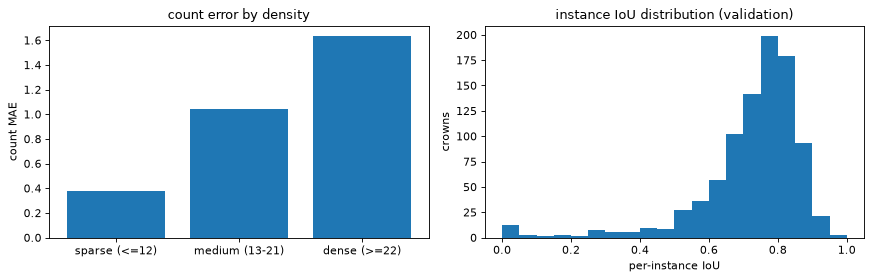

In [12]:
# Split the validation forests by density (ground-truth tree count).
buckets = {"sparse (<=12)": [], "medium (13-21)": [], "dense (>=22)": []}
bucket_ious = {key: [] for key in buckets}
for sample_idx in range(n_forest_val):
    tree_count = max(int(val_instances[sample_idx].max()), 1)
    if tree_count <= 12:
        key = "sparse (<=12)"
    elif tree_count <= 21:
        key = "medium (13-21)"
    else:
        key = "dense (>=22)"
    buckets[key].append(sample_idx)
    sample_ious, _ = forest_instance_scores(val_instances[sample_idx], predicted_labels[sample_idx])
    bucket_ious[key].extend(sample_ious)

for key in buckets:
    count = len(buckets[key])
    if count:
        mae = np.mean([count_errors[i] for i in buckets[key]])
        iou = np.mean(bucket_ious[key]) if bucket_ious[key] else 0.0
        print(f"{key:15s} n={count:2d} | count MAE {mae:.2f} | mean IoU {iou:.3f}")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=80)
keys = list(buckets)
axes[0].bar(
    keys, [np.mean([count_errors[i] for i in buckets[k]]) if buckets[k] else 0 for k in keys]
)
axes[0].set_ylabel("count MAE")
axes[0].set_title("count error by density")
axes[1].hist([iou for values in bucket_ious.values() for iou in values], bins=20, range=(0, 1))
axes[1].set_xlabel("per-instance IoU")
axes[1].set_ylabel("crowns")
axes[1].set_title("instance IoU distribution (validation)")
plt.tight_layout()
plt.show()

**Figure read-out.** Count MAE by canopy density and the per-instance IoU histogram: the count error grows with the canopy density (MAE about 0.4 trees on sparse stands, 1.0 on medium and 1.6 on dense ones) and the instance IoU falls for dense canopies (about 0.64, against 0.76-0.77 for sparse and medium).

### Interpreting these numbers

The model works on 64x64 forest tiles with light sensor noise and a little blur,
where dense crowns overlap heavily, some trees are almost fully hidden, and grey
**boulders** add non-tree blobs: an exact per-tree mask is simply not
recoverable from the image everywhere.

So the right reading is not "the model is bad" but "these metrics quantify
robustness under realistic conditions":

- High scores on clean renders can mislead; a model that never sees noise or
  overlap can look near-perfect and fail on the first degraded acquisition.
- Overlap, occlusion and a few pixels per crown set a **ceiling** that no
  architecture can beat.
- Some errors are **irreducible** (a fully occluded crown).
- A count and a mask are different questions: report the **count error**, the
  **instance IoU** and the **detection rate** together, and read them by canopy
  density rather than as one average.
